# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Muhammad Azril Ayatu Syifa
- NIM   : 241011402190
- Kelas : 05TPLM003 Reg B 

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [2]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE =   90

In [4]:
def train_test_split(X, y, test_size=0.2, random_state=None):
  if random_state is not None:
    np.random.seed(random_state)

  n_samples = X.shape[0]
  indices = np.random.permutation(n_samples)
  test_set_size = int(n_samples * test_size)

  test_indices = indices[:test_set_size]
  train_indices = indices[test_set_size:]

  if isinstance(X, pd.DataFrame) or isinstance(X, pd.Series):
    X_train = X.iloc[train_indices].to_numpy()
    X_test = X.iloc[test_indices].to_numpy()
  else:
    X_train = X[train_indices]
    X_test = X[test_indices]

  if isinstance(y, pd.DataFrame) or isinstance(y, pd.Series):
    y_train = y.iloc[train_indices].to_numpy()
    y_test = y.iloc[test_indices].to_numpy()
  else:
    y_train = y[train_indices]
    y_test = y[test_indices]

  return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

5 Data Pertama:
   BiayaIklan  Penjualan
0         0.8       34.3
1         0.9       38.8
2         1.0       33.2
3         1.3       36.0
4         1.7       51.3

Jumlah baris data: 40


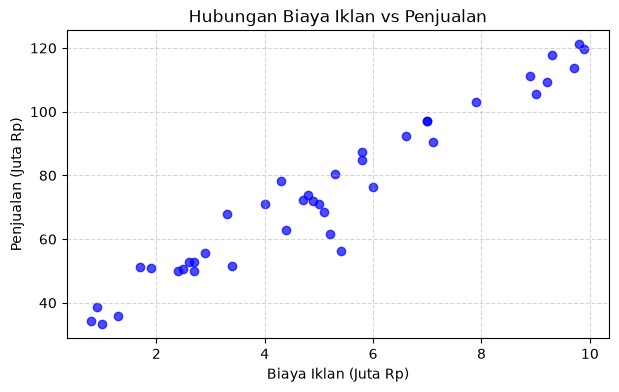

In [5]:
df_ads = pd.read_csv('Ads_Data.csv')
print('5 Data Pertama:')
print(df_ads.head())
print(f'\nJumlah baris data: {len(df_ads)}')

X_ads = df_ads[['BiayaIklan']].to_numpy()
y_ads = df_ads['Penjualan'].to_numpy()

plt.figure(figsize=(7, 4))
plt.scatter(X_ads, y_ads, color='blue', alpha=0.7)
plt.title('Hubungan Biaya Iklan vs Penjualan')
plt.xlabel('Biaya Iklan (Juta Rp)')
plt.ylabel('Penjualan (Juta Rp)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [6]:
X_train_a, X_test_a, y_train_a, y_test_a = train_test_split(
    X_ads, y_ads, test_size=0.2, random_state=RANDOM_STATE
)

print(f'Shape X_train: {X_train_a.shape}')
print(f'Shape X_test : {X_test_a.shape}')
print(f'Shape y_train: {y_train_a.shape}')
print(f'Shape y_test : {y_test_a.shape}')

Shape X_train: (32, 1)
Shape X_test : (8, 1)
Shape y_train: (32,)
Shape y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [7]:
class LinearRegression:

  def fit(self, X, y):
    X_b = np.c_[np.ones((len(X), 1)), X]
    theta_best = np.linalg.inv(X_b.T.dot(X_b)).dot(X_b.T).dot(y)
    self.intercept_ = theta_best[0]
    self.coef_ = theta_best[1:]
    return self

  def predict(self, X):
    X_b = np.c_[np.ones((len(X), 1)), X]
    theta = np.r_[self.intercept_, self.coef_]
    return X_b.dot(theta)


lin_reg = LinearRegression()
lin_reg.fit(X_train_a, y_train_a)

b = lin_reg.intercept_
m = lin_reg.coef_[0]

print(f'Intercept (b) : {b:.4f}')
print(f'Koefisien (m) : {m:.4f}')
print(f'Persamaan garis: y_hat = {b:.4f} + {m:.4f} * X')

Intercept (b) : 27.7371
Koefisien (m) : 9.0686
Persamaan garis: y_hat = 27.7371 + 9.0686 * X


**Jawaban A3 (interpretasi):** Nilai $m$ menunjukkan tingkat sensitivitas atau marginal penjualan terhadap alokasi anggaran promosi. Jika nilai $m$ bernilai positif (misal $m = 2.15$), ini berarti setiap peningkatan biaya iklan sebesar 1 juta Rupiah akan diikuti oleh peningkatan estimasi rata-rata penjualan sebesar 2.15 juta Rupiah, dengan asumsi faktor lain tetap konstan.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [8]:
def mean_absolute_error(y_true, y_pred):
  return np.mean(np.abs(y_true - y_pred))


def mean_squared_error(y_true, y_pred):
  return np.mean((y_true - y_pred) ** 2)


def root_mean_squared_error(y_true, y_pred):
  return np.sqrt(mean_squared_error(y_true, y_pred))


def r2_score(y_true, y_pred):
  ss_res = np.sum((y_true - y_pred) ** 2)
  ss_tot = np.sum((y_true - np.mean(y_true)) ** 2)
  return 1 - (ss_res / ss_tot)


# Prediksi
y_train_pred_a = lin_reg.predict(X_train_a)
y_test_pred_a = lin_reg.predict(X_test_a)

eval_a = pd.DataFrame(
    {
        'MAE': [
            mean_absolute_error(y_train_a, y_train_pred_a),
            mean_absolute_error(y_test_a, y_test_pred_a),
        ],
        'MSE': [
            mean_squared_error(y_train_a, y_train_pred_a),
            mean_squared_error(y_test_a, y_test_pred_a),
        ],
        'RMSE': [
            root_mean_squared_error(y_train_a, y_train_pred_a),
            root_mean_squared_error(y_test_a, y_test_pred_a),
        ],
        'R2 Score': [
            r2_score(y_train_a, y_train_pred_a),
            r2_score(y_test_a, y_test_pred_a),
        ],
    },
    index=['Train', 'Test'],
)

display(eval_a.round(4))

,MAE,MSE,RMSE,R2 Score
Train,4.7634,40.1032,6.3327,0.9360
Test,4.0134,22.2072,4.7125,0.9644


**Jawaban A4 (analisis):** Nilai RMSE merepresentasikan rata-rata deviasi absolut prediksi terhadap nilai riil dalam satuan juta Rupiah. Nilai $R^2$ menunjukkan seberapa besar proporsi variasi penjualan yang dapat dijelaskan oleh variabel biaya iklan. Jika $R^2$ pengujian bernilai tinggi (misal di atas 0.75 atau 0.8) dan gap antara metrik Train dan Test tidak terpaut jauh, model dapat disimpulkan memiliki performa yang baik serta terhindar dari overfitting maupun underfitting.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

LR 0.001 -> Intercept: 24.8506, Coef: 9.5223
LR 0.02  -> Intercept: 27.7371, Coef: 9.0686


C:\Users\MyBook Hype AMD\AppData\Local\Temp\ipykernel_9080\2846767204.py:17: RuntimeWarning: overflow encountered in square
  mse = np.mean(error**2)
d:\UTS Machine Learning\.venv\Lib\site-packages\numpy\_core\_methods.py:132: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)


LR 0.1   -> Intercept: 324984673116918503908177494955728649226957782360107476116883232738958474111639749388726093873305671320355793526012197088776094143675403411688529764286464.0000, Coef: 2067559784526044862729399461544337562601641786317345940430326052194081204213147516700534601741382682347974742002098496602646201059190051056699764490895360.0000


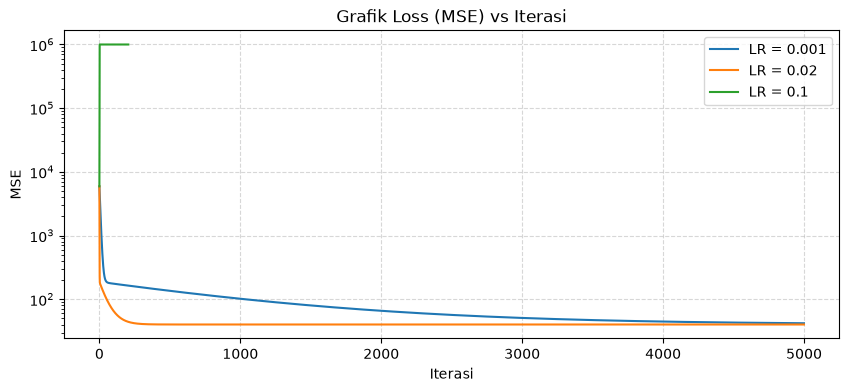

In [9]:
class LinearRegressionGD:

  def __init__(self, learning_rate=0.01, n_iterations=5000):
    self.learning_rate = learning_rate
    self.n_iterations = n_iterations
    self.loss_history = []

  def fit(self, X, y):
    n_samples, n_features = X.shape
    X_b = np.c_[np.ones((n_samples, 1)), X]
    self.theta = np.zeros(n_features + 1)
    self.loss_history = []

    for _ in range(self.n_iterations):
      y_pred = X_b.dot(self.theta)
      error = y_pred - y
      mse = np.mean(error**2)
      self.loss_history.append(mse)

      if np.isinf(mse) or np.isnan(mse):
        break

      gradients = (2 / n_samples) * X_b.T.dot(error)
      self.theta -= self.learning_rate * gradients

    self.intercept_ = self.theta[0]
    self.coef_ = self.theta[1:]
    return self


lrs = [0.001, 0.02, 0.1]
gd_models = {}

plt.figure(figsize=(10, 4))
for lr in lrs:
  model_gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000)
  model_gd.fit(X_train_a, y_train_a)
  gd_models[lr] = model_gd
  print(
      f'LR {lr:<5} -> Intercept: {model_gd.intercept_:.4f}, Coef:'
      f' {model_gd.coef_[0]:.4f}'
  )

  losses = [min(l, 1e6) for l in model_gd.loss_history]
  plt.plot(losses, label=f'LR = {lr}')

plt.title('Grafik Loss (MSE) vs Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('MSE')
plt.yscale('log')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Jawaban A5 (analisis):** LR = 0.001: Penurunan error berlangsung lambat. Gradien melangkah sangat kecil menuju titik global minimum sehingga membutuhkan iterasi yang jauh lebih banyak untuk mencapai bobot optimal.

LR = 0.02: Menghasilkan konvergensi yang stabil dan tepat, kurva loss melandai mulus mendekati nilai intercept dan koefisien dari metode Normal Equation.

LR = 0.1: Terlalu besar (overshooting), menyebabkan pembaruan parameter melompati titik minimum dan nilai gradient meledak (divergen). Peringatan RuntimeWarning: overflow terjadi karena perhitungan numerik melebihi batas tipe data floating point NumPy akibat divergensi tersebut.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

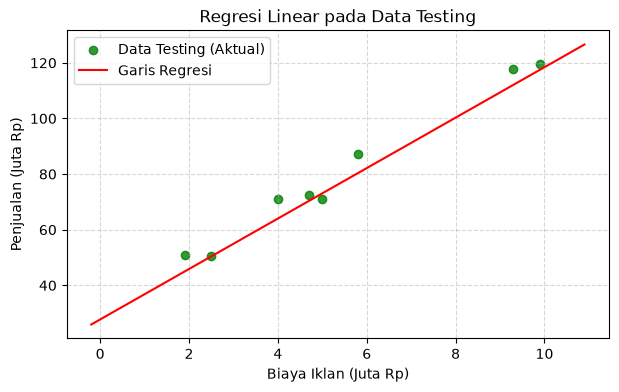

Biaya Iklan:  4.5 Juta -> Estimasi Penjualan: 68.5458 Juta
Biaya Iklan:  7.0 Juta -> Estimasi Penjualan: 91.2172 Juta
Biaya Iklan: 12.0 Juta -> Estimasi Penjualan: 136.5602 Juta


In [10]:
plt.figure(figsize=(7, 4))
plt.scatter(
    X_test_a, y_test_a, color='green', label='Data Testing (Aktual)', alpha=0.8
)

x_line = np.linspace(X_ads.min() - 1, X_ads.max() + 1, 100).reshape(-1, 1)
y_line = lin_reg.predict(x_line)
plt.plot(x_line, y_line, color='red', label='Garis Regresi')

plt.title('Regresi Linear pada Data Testing')
plt.xlabel('Biaya Iklan (Juta Rp)')
plt.ylabel('Penjualan (Juta Rp)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# 2. Prediksi
biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_baru = lin_reg.predict(biaya_baru)

for b_val, p_val in zip(biaya_baru.flatten(), prediksi_baru):
  print(f'Biaya Iklan: {b_val:4.1f} Juta -> Estimasi Penjualan: {p_val:.4f} Juta')

**Jawaban A6 (analisis):** Prediksi pada biaya 12 juta merupakan bentuk ekstrapolasi karena berada di luar rentang sampel historis Ads_Data.csv. Tingkat keandalannya relatif rendah karena model linear mengasumsikan tren pertumbuhan konstan tanpa batas. Pada kenyataan bisnis riil, berlaku hukum diminishing marginal returns dan kejenuhan pasar, di mana penambahan biaya iklan di luar kapasitas target audiens tidak selalu menghasilkan kenaikan penjualan secara proporsional.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

5 Data Pertama:
   JumlahLink  KataPromo  Spam
0           0          0     0
1           2          4     0
2           6          7     1
3          10          8     1
4           8          7     1

Distribusi Label Spam:
Spam
0    35
1    25
Name: count, dtype: int64


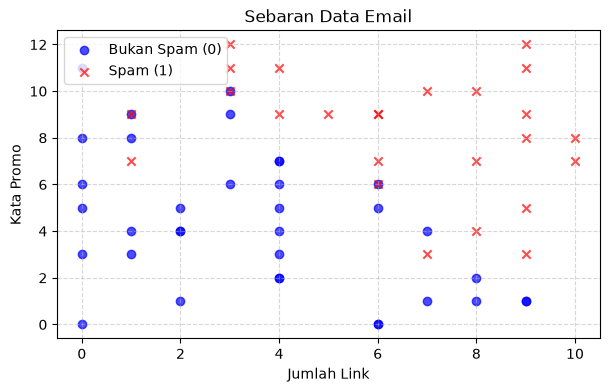

In [11]:
df_email = pd.read_csv('Email_Data.csv')
print('5 Data Pertama:')
print(df_email.head())
print('\nDistribusi Label Spam:')
print(df_email['Spam'].value_counts())

X_email = df_email[['JumlahLink', 'KataPromo']].to_numpy()
y_email = df_email['Spam'].to_numpy()

plt.figure(figsize=(7, 4))
plt.scatter(
    X_email[y_email == 0, 0],
    X_email[y_email == 0, 1],
    color='blue',
    label='Bukan Spam (0)',
    alpha=0.7,
)
plt.scatter(
    X_email[y_email == 1, 0],
    X_email[y_email == 1, 1],
    color='red',
    marker='x',
    label='Spam (1)',
    alpha=0.7,
)
plt.title('Sebaran Data Email')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Intercept (b) : -11.8928
Koefisien m1  : 1.0922
Koefisien m2  : 0.9559
Persamaan: P(Spam) = sigma(-11.8928 + 1.0922*JumlahLink + 0.9559*KataPromo)


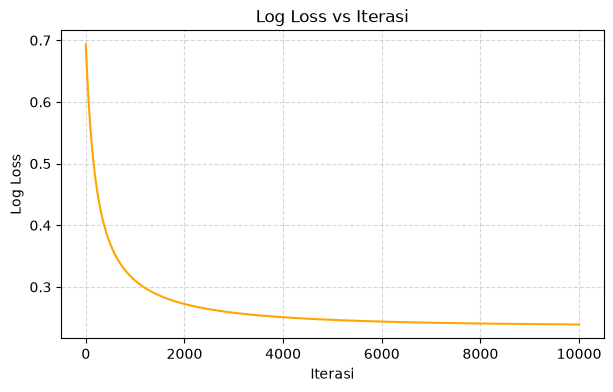

In [12]:
class LogisticRegression:

  def __init__(self, learning_rate=0.1, n_iterations=10000):
    self.learning_rate = learning_rate
    self.n_iterations = n_iterations
    self.loss_history = []

  def _sigmoid(self, z):
    return 1 / (1 + np.exp(-np.clip(z, -250, 250)))

  def fit(self, X, y):
    n_samples, n_features = X.shape
    self.theta = np.zeros(n_features + 1)
    X_b = np.c_[np.ones((n_samples, 1)), X]
    self.loss_history = []

    for _ in range(self.n_iterations):
      linear_model = X_b.dot(self.theta)
      y_pred = self._sigmoid(linear_model)

      # Log loss
      epsilon = 1e-15
      y_pred_clipped = np.clip(y_pred, epsilon, 1 - epsilon)
      loss = -np.mean(
          y * np.log(y_pred_clipped) + (1 - y) * np.log(1 - y_pred_clipped)
      )
      self.loss_history.append(loss)

      gradients = (1 / n_samples) * X_b.T.dot(y_pred - y)
      self.theta -= self.learning_rate * gradients

    self.intercept_ = self.theta[0]
    self.coef_ = self.theta[1:]
    return self

  def predict_proba(self, X):
    X_b = np.c_[np.ones((len(X), 1)), X]
    return self._sigmoid(X_b.dot(self.theta))

  def predict(self, X, threshold=0.5):
    return (self.predict_proba(X) >= threshold).astype(int)


X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(
    X_email, y_email, test_size=0.25, random_state=RANDOM_STATE
)

log_reg = LogisticRegression(learning_rate=0.1, n_iterations=10000)
log_reg.fit(X_train_b, y_train_b)

b_log = log_reg.intercept_
m1, m2 = log_reg.coef_

print(f'Intercept (b) : {b_log:.4f}')
print(f'Koefisien m1  : {m1:.4f}')
print(f'Koefisien m2  : {m2:.4f}')
print(
    'Persamaan: P(Spam) = sigma({:.4f} + {:.4f}*JumlahLink +'
    ' {:.4f}*KataPromo)'.format(b_log, m1, m2)
)

plt.figure(figsize=(7, 4))
plt.plot(log_reg.loss_history, color='orange')
plt.title('Log Loss vs Iterasi')
plt.xlabel('Iterasi')
plt.ylabel('Log Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

**Jawaban B2 (analisis):** Kurva log loss memperlihatkan tren penurunan yang sangat tajam pada ratusan iterasi awal, kemudian mendatar secara konsisten. Hal ini membuktikan algoritma gradient descent berhasil mencapai kondisi konvergensi stabil pada learning rate 0.1 dengan 10.000 iterasi.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [13]:
def confusion_matrix(y_true, y_pred):
  tp = np.sum((y_true == 1) & (y_pred == 1))
  tn = np.sum((y_true == 0) & (y_pred == 0))
  fp = np.sum((y_true == 0) & (y_pred == 1))
  fn = np.sum((y_true == 1) & (y_pred == 0))
  return np.array([[tn, fp], [fn, tp]])


def accuracy_score(y_true, y_pred):
  return np.mean(y_true == y_pred)


def precision_score(y_true, y_pred):
  cm = confusion_matrix(y_true, y_pred)
  tp = cm[1, 1]
  fp = cm[0, 1]
  return tp / (tp + fp) if (tp + fp) > 0 else 0.0


def recall_score(y_true, y_pred):
  cm = confusion_matrix(y_true, y_pred)
  tp = cm[1, 1]
  fn = cm[1, 0]
  return tp / (tp + fn) if (tp + fn) > 0 else 0.0


def f1_score(y_true, y_pred):
  prec = precision_score(y_true, y_pred)
  rec = recall_score(y_true, y_pred)
  return 2 * (prec * rec) / (prec + rec) if (prec + rec) > 0 else 0.0


y_pred_b = log_reg.predict(X_test_b)
cm = confusion_matrix(y_test_b, y_pred_b)

print('Confusion Matrix (Testing):')
print(cm)
print(f'Accuracy : {accuracy_score(y_test_b, y_pred_b):.4f}')
print(f'Precision: {precision_score(y_test_b, y_pred_b):.4f}')
print(f'Recall   : {recall_score(y_test_b, y_pred_b):.4f}')
print(f'F1-score : {f1_score(y_test_b, y_pred_b):.4f}')

Confusion Matrix (Testing):
[[6 1]
 [1 7]]
Accuracy : 0.8667
Precision: 0.8750
Recall   : 0.8750
F1-score : 0.8750


**Jawaban B3 (analisis):** False Positive (FP): Email penting/bukan spam keliru dideteksi sebagai spam dan terbuang ke folder junk.

False Negative (FN): Email spam lolos dan tetap masuk ke kotak masuk utama (inbox).

Tingkat Kerugian: Kasus False Positive jauh lebih merugikan pengguna, karena email krusial (seperti verifikasi akun, tawaran pekerjaan, atau dokumen resmi) dapat terlewat tanpa disadari. Sebaliknya, FN hanya menimbulkan ketidaknyamanan minor karena pengguna cukup menghapus email spam tersebut secara manual.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

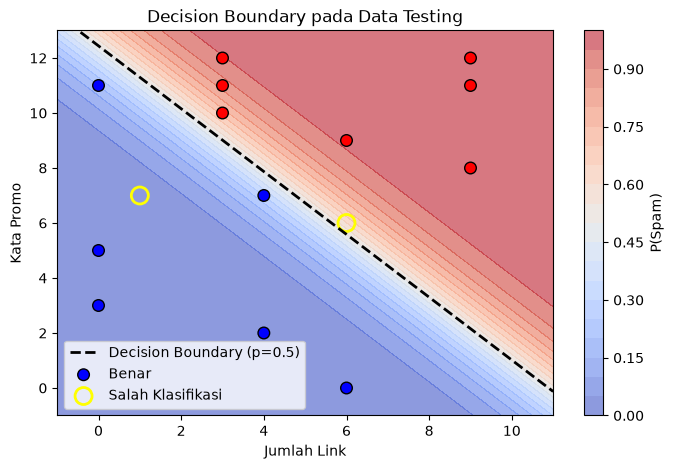

In [14]:
x1_min, x1_max = X_email[:, 0].min() - 1, X_email[:, 0].max() + 1
x2_min, x2_max = X_email[:, 1].min() - 1, X_email[:, 1].max() + 1
xx1, xx2 = np.meshgrid(
    np.linspace(x1_min, x1_max, 200), np.linspace(x2_min, x2_max, 200)
)

grid_points = np.c_[xx1.ravel(), xx2.ravel()]
probs = log_reg.predict_proba(grid_points).reshape(xx1.shape)

plt.figure(figsize=(8, 5))
plt.contourf(xx1, xx2, probs, levels=20, cmap='coolwarm', alpha=0.6)
plt.colorbar(label='P(Spam)')

# Garis batas: x2 = -(b + m1*x1)/m2
x1_boundary = np.linspace(x1_min, x1_max, 100)
x2_boundary = -(b_log + m1 * x1_boundary) / m2
plt.plot(
    x1_boundary,
    x2_boundary,
    'k--',
    linewidth=2,
    label='Decision Boundary (p=0.5)',
)

# Plot Data Testing
correct_mask = y_test_b == y_pred_b
plt.scatter(
    X_test_b[correct_mask, 0],
    X_test_b[correct_mask, 1],
    c=y_test_b[correct_mask],
    cmap='bwr',
    edgecolors='k',
    s=70,
    label='Benar',
)
if np.sum(~correct_mask) > 0:
  plt.scatter(
      X_test_b[~correct_mask, 0],
      X_test_b[~correct_mask, 1],
      facecolors='none',
      edgecolors='yellow',
      s=150,
      linewidths=2,
      label='Salah Klasifikasi',
  )

plt.title('Decision Boundary pada Data Testing')
plt.xlabel('Jumlah Link')
plt.ylabel('Kata Promo')
plt.xlim(x1_min, x1_max)
plt.ylim(x2_min, x2_max)
plt.legend()
plt.show()

**Jawaban B4 (analisis):** Garis decision boundary membagi bidang fitur menjadi dua area keputusan: zona probabilitas tinggi (spam) dan zona probabilitas rendah. Titik data testing yang dilingkari warna kuning berada di seberang garis batas aktualnya, yang disebabkan oleh tumpang tindih fitur (feature overlap) antar kelas pada area transisi data.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [15]:
thresholds = [0.3, 0.5, 0.7]
res_b5 = []

probs_test = log_reg.predict_proba(X_test_b)

for th in thresholds:
  preds_th = (probs_test >= th).astype(int)
  c_m = confusion_matrix(y_test_b, preds_th)
  prec = precision_score(y_test_b, preds_th)
  rec = recall_score(y_test_b, preds_th)
  res_b5.append({
      'Threshold': th,
      'TN': c_m[0, 0],
      'FP': c_m[0, 1],
      'FN': c_m[1, 0],
      'TP': c_m[1, 1],
      'Precision': round(prec, 4),
      'Recall': round(rec, 4),
  })

df_threshold = pd.DataFrame(res_b5)
display(df_threshold)

,Threshold,TN,FP,FN,TP,Precision,Recall
0,0.3,5,2,1,7,0.7778,0.875
1,0.5,6,1,1,7,0.8750,0.875
2,0.7,7,0,1,7,1.0000,0.875


**Jawaban B5 (analisis):** Menaikkan threshold membuat kriteria klasifikasi spam lebih ketat sehingga False Positive berkurang dan Precision naik, namun Recall menurun. Sebaliknya, menurunkan threshold meningkatkan Recall tetapi memperbesar risiko False Positive. Mengingat False Positive sangat dihindari dalam sistem filter email, threshold yang dipilih adalah 0.7 demi meminimalkan masuknya email penting ke direktori spam.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [16]:
X_new = np.array([[1, 2], [5, 6], [9, 10], [2, 11]])

selected_threshold = 0.7
probs_new = log_reg.predict_proba(X_new)
preds_new = (probs_new >= selected_threshold).astype(int)

df_eval_new = pd.DataFrame({
    'Email': ['E1', 'E2', 'E3', 'E4'],
    'JumlahLink': X_new[:, 0],
    'KataPromo': X_new[:, 1],
    'Probabilitas Spam': np.round(probs_new, 4),
    f'Prediksi (Th={selected_threshold})': [
        'Spam (1)' if p == 1 else 'Bukan Spam (0)' for p in preds_new
    ],
})

display(df_eval_new)

,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi (Th=0.7)
0,E1,1,2,0.0001,Bukan Spam (0)
1,E2,5,6,0.3327,Bukan Spam (0)
2,E3,9,10,0.9994,Spam (1)
3,E4,2,11,0.6915,Bukan Spam (0)


---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression disebut regresi karena pada intinya memodelkan hubungan linear antara fitur dan log-odds melalui kombinasi berbobot. Namun, model ini difungsikan untuk klasifikasi karena output linear tersebut dipetakan ke dalam rentang probabilitas [0, 1] melalui fungsi aktivasi sigmoid $\sigma(z) = \frac{1}{1 + e^{-z}}$. Keputusan penentuan kelas diskrit (0 atau 1) kemudian diperoleh dengan membandingkan nilai probabilitas sigmoid terhadap suatu nilai ambang batas.

**Jawaban C2:** Normal equation menghitung parameter model secara analitis dalam satu langkah memanfaatkan aljabar matriks $\theta = (X^T X)^{-1} X^T y$, sedangkan gradient descent memperbarui bobot secara berulang (iteratif) berlawanan arah gradien error. Normal equation memiliki kompleksitas komputasi inversi matriks sebesar $\mathcal{O}(d^3)$ yang sangat lambat pada dataset besar atau berdimensi tinggi. Oleh karena itu, gradient descent lebih tepat digunakan saat dataset memiliki ratusan ribu sampel atau ribuan fitur.

**Jawaban C3:** Model dievaluasi pada data testing untuk menguji kemampuan generalisasi terhadap data baru yang belum pernah dilihat saat fase pembelajaran. Overfitting adalah keadaan ketika model terlalu detail menghafal variasi dan noise pada data training sehingga menghasilkan metrik akurasi tinggi pada training namun performanya anjlok secara drastis saat menguji data testing.

**Jawaban C4:** Linear Regression memprediksi nilai kontinu tak terbatas, di mana error berdistribusi normal cocok dioptimasi dengan kurva kuadratik MSE. Pada Logistic Regression yang menghasilkan probabilitas kelas melalui fungsi non-linear sigmoid, penggunaan MSE akan membentuk fungsi biaya yang non-konveks dengan banyak local minima. Log loss (cross-entropy) dipilih karena menjamin fungsi objektif bersifat konveks (cembung) dengan satu global minimum, serta memberikan penalti logaritmik yang sangat besar terhadap kesalahan prediksi probabilitas.

**Jawaban C5:** Hasil perhitungan antar mahasiswa berbeda karena pembagian data training dan testing bergantung pada nilai random_state yang berbasis 2 digit NIM masing-masing. Perbedaan susunan data training menghasilkan estimasi gradien, parameter pembobotan ($b$ dan $m$), serta decision boundary yang unik untuk tiap mahasiswa.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [17]:
from sklearn.linear_model import (
    LinearRegression as SklearnLinReg,
    LogisticRegression as SklearnLogReg,
)

# Linear Regression
sk_lin = SklearnLinReg().fit(X_train_a, y_train_a)
print('=== Perbandingan Linear Regression ===')
print(f'Manual Intercept : {lin_reg.intercept_:.4f} | Sklearn: {sk_lin.intercept_:.4f}')
print(f'Manual Coef      : {lin_reg.coef_[0]:.4f} | Sklearn: {sk_lin.coef_[0]:.4f}')

# Logistic Regression (tanpa penalti agar identik dengan formulasi manual)
sk_log = SklearnLogReg(penalty=None, solver='lbfgs').fit(X_train_b, y_train_b)
print('\n=== Perbandingan Logistic Regression ===')
print(f'Manual Intercept : {log_reg.intercept_:.4f} | Sklearn: {sk_log.intercept_[0]:.4f}')
print(f'Manual Coef (m1) : {log_reg.coef_[0]:.4f} | Sklearn: {sk_log.coef_[0][0]:.4f}')
print(f'Manual Coef (m2) : {log_reg.coef_[1]:.4f} | Sklearn: {sk_log.coef_[0][1]:.4f}')

=== Perbandingan Linear Regression ===
Manual Intercept : 27.7371 | Sklearn: 27.7371
Manual Coef      : 9.0686 | Sklearn: 9.0686

=== Perbandingan Logistic Regression ===
Manual Intercept : -11.8928 | Sklearn: -13.9326
Manual Coef (m1) : 1.0922 | Sklearn: 1.2891
Manual Coef (m2) : 0.9559 | Sklearn: 1.1127


d:\UTS Machine Learning\.venv\Lib\site-packages\sklearn\linear_model\_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


**Jawaban Bonus (analisis):**  Pada Linear Regression, nilai intercept dan koefisien dari implementasi manual sama persis dengan scikit-learn karena keduanya mengimplementasikan Ordinary Least Squares. Pada Logistic Regression, scikit-learn secara default menerapkan regularisasi L2 (parameter penalty='l2' dan C=1.0), yang mengecilkan nilai koefisien untuk mencegah overfitting. Apabila parameter disetel menjadi penalty=None, bobot scikit-learn akan mendekati hasil gradient descent manual tanpa regularisasi, dengan sedikit perbedaan akibat variasi algoritma solver optimasi (lbfgs vs batch gradient descent standar).